In [1]:
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
!ls "/content/drive/My Drive/"
#Reading Dataset

data=pd.read_csv('/content/drive/My Drive/train.csv')
data.head(12)



Mounted at /content/drive
 aclImdb	    gt_2012.csv   movies.csv	        RT_IOT2022.csv
 CO2.csv	    gt_2013.csv   movies_metadata.csv   train.csv
'Colab Notebooks'   gt_2014.csv   neg
 glove.6B.50d.txt   gt_2015.csv  'Online Retail.xlsx'
 gt_2011.csv	    l34.csv	  ratings.csv


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,55444,7315,21,tcp,-,0.000001,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
1,15766,18609,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
2,63311,14663,21,tcp,-,0.000002,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
3,3245,37827,1883,tcp,mqtt,62.052435,9,5,3,3,...,0.0,5.981909e+07,5.981909e+07,5.981909e+07,5.981909e+07,0.0,64240,26847,502,MQTT_Publish
4,94007,22348,21,tcp,-,0.000000,1,0,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
5,78072,37150,21,tcp,-,0.000005,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
6,78191,36115,21,tcp,-,0.000005,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
7,39338,42253,21,tcp,-,0.000004,1,1,1,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,64,0,64,DOS_SYN_Hping
8,721,36242,1334,tcp,-,0.000009,1,1,0,0,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,1024,0,1024,NMAP_XMAS_TREE_SCAN
9,2554,49275,53,udp,dns,0.021367,2,2,2,2,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0,0,0,Thing_Speak


In [18]:
# import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
# Suppose X has shape (samples, features) = (10000, 85)
# Reshape for Conv1D: (samples, timesteps, channels)

# Identify categorical columns (including attack_type)
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()

# Exclude the label column from encoding
categorical_cols.remove('Attack_type')

# Apply Label Encoding to all categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le  # Save encoder for future use (optional)

# Encode the target label 'attack_type'
target_encoder = LabelEncoder()
data['Attack_type'] = target_encoder.fit_transform(data['Attack_type'])

# Features and labels
X = data.drop('Attack_type', axis=1)
y = data['Attack_type']

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# X = data.drop('Cylinders', axis=1)
# X = X.apply(pd.to_numeric, errors='coerce')
# y = data['Cylinders']


X_reshaped = X.values.reshape(-1, 84, 1)

model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(84, 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='softmax')  # or softmax for multi-class
])

model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_reshaped, y, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/ops/nn.py:907: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._f

3078/3078 ━━━━━━━━━━━━━━━━━━━━ 19s 6ms/step - accuracy: 0.0787 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 2/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0776 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 3/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.0776 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 4/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.0790 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 5/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.0779 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 6/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.0789 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 7/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0806 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan
Epoch 8/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.0793 - loss: nan - val_accuracy: 0.0000

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Example preprocessing steps (assuming you have the 'data' DataFrame)
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove('Attack_type')  # Exclude target column

# Apply Label Encoding to all categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Encode the target label 'attack_type'
target_encoder = LabelEncoder()
data['Attack_type'] = target_encoder.fit_transform(data['Attack_type'])

# Features and labels
X = data.drop('Attack_type', axis=1)
y = data['Attack_type']

# One-hot encode the target labels (y)
y_one_hot = to_categorical(y, num_classes=len(target_encoder.classes_))  # One-hot encoding

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape for Conv1D (assuming 84 features)
X_reshaped = X_scaled.reshape(-1, 84, 1)

# Define the model
model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(84, 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(len(target_encoder.classes_), activation='softmax')  # Output layer size matches number of classes
])

# Compile the model
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_reshaped, y_one_hot, epochs=10, batch_size=32, validation_split=0.2)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9341 - loss: 0.2930 - val_accuracy: 0.6886 - val_loss: 2.4288
Epoch 2/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9774 - loss: 0.0639 - val_accuracy: 0.6886 - val_loss: 2.8410
Epoch 3/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9812 - loss: 0.0496 - val_accuracy: 0.6886 - val_loss: 2.9833
Epoch 4/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.9842 - loss: 0.0426 - val_accuracy: 0.6886 - val_loss: 3.1919
Epoch 5/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - accuracy: 0.9864 - loss: 0.0430 - val_accuracy: 0.6886 - val_loss: 3.2990
Epoch 6/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.9888 - loss: 0.0376 - val_accuracy: 0.6886 - val_loss: 3.3648
Epoch 7/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - accuracy: 0.9906 - loss: 0.0330 - val_accuracy: 0.6886 - val_loss: 3.4041
Epoch 8/10
3078/3078 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - accuracy: 0.9921 - loss: 0

In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Example preprocessing steps (assuming you have the 'data' DataFrame)
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove('Attack_type')  # Exclude target column

# Apply Label Encoding to all categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Encode the target label 'attack_type'
target_encoder = LabelEncoder()
data['Attack_type'] = target_encoder.fit_transform(data['Attack_type'])

# Features and labels
X = data.drop('Attack_type', axis=1)
y = data['Attack_type']

# One-hot encode the target labels (y)
y_one_hot = to_categorical(y, num_classes=len(target_encoder.classes_))  # One-hot encoding

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape for Conv1D (assuming 84 features)
X_reshaped = X_scaled.reshape(-1, 84, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X_reshaped, y_one_hot, test_size=0.2, stratify=y, random_state=42
)
# Define the model
model = Sequential([
    Conv1D(filters=16, kernel_size=3, activation='relu', input_shape=(84, 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(len(target_encoder.classes_), activation='softmax')  # Output layer size matches number of classes
])
# model.add(Dropout(0.5))  # Dropout with 50% probability

# Compile the model
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_reshaped, y_one_hot, epochs=10, batch_size=32,validation_data=(X_val, y_val))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9286 - loss: 0.3230 - val_accuracy: 0.9780 - val_loss: 0.0716
Epoch 2/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.9794 - loss: 0.0661 - val_accuracy: 0.9803 - val_loss: 0.0568
Epoch 3/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.9827 - loss: 0.0537 - val_accuracy: 0.9795 - val_loss: 0.0583
Epoch 4/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.9850 - loss: 0.0453 - val_accuracy: 0.9877 - val_loss: 0.0402
Epoch 5/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.9882 - loss: 0.0373 - val_accuracy: 0.9912 - val_loss: 0.0354
Epoch 6/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.9898 - loss: 0.0334 - val_accuracy: 0.9918 - val_loss: 0.0339
Epoch 7/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 22s 4ms/step - accuracy: 0.9917 - loss: 0.0306 - val_accuracy: 0.9918 - val_loss: 0.0322
Epoch 8/10
3848/3848 ━━━━━━━━━━━━━━━━━━━━ 16s 4ms/step - accuracy: 0.9917 - loss: 0

In [34]:
from sklearn.metrics import classification_report
y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_val, axis=1)
print(classification_report(y_true, y_pred_classes))

770/770 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
              precision    recall  f1-score   support

           0       0.98      0.92      0.95      1550
           1       0.99      0.80      0.89       107
           2       1.00      1.00      1.00     18932
           3       1.00      1.00      1.00       829
           4       0.67      0.57      0.62         7
           5       1.00      0.83      0.91         6
           6       1.00      1.00      1.00       400
           7       1.00      1.00      1.00       200
           8       0.96      0.99      0.97       518
           9       1.00      1.00      1.00       402
          10       0.92      0.99      0.95      1622
          11       1.00      0.53      0.69        51

    accuracy                           0.99     24624
   macro avg       0.96      0.89      0.91     24624
weighted avg       0.99      0.99      0.99     24624



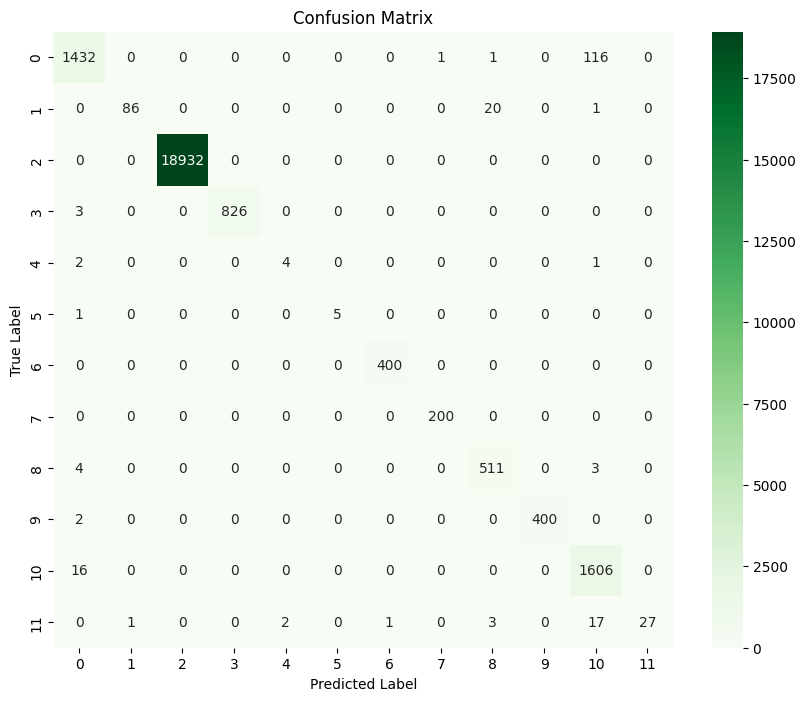

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(X_val, y_val_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Example preprocessing steps (assuming you have the 'data' DataFrame)
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove('Attack_type')  # Exclude target column

# Apply Label Encoding to all categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Encode the target label 'attack_type'
target_encoder = LabelEncoder()
data['Attack_type'] = target_encoder.fit_transform(data['Attack_type'])

# Features and labels
X = data.drop('Attack_type', axis=1)
y = data['Attack_type']

# One-hot encode the target labels (y)
y_one_hot = to_categorical(y, num_classes=len(target_encoder.classes_))  # One-hot encoding

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reshape for Conv1D (assuming 84 features)
X_reshaped = X_scaled.reshape(-1, 84, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X_reshaped, y_one_hot, test_size=0.2, stratify=y, random_state=42
)
# Define the model
model = Sequential([
    Conv1D(filters=16, kernel_size=3, activation='relu', input_shape=(84, 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(len(target_encoder.classes_), activation='softmax')  # Output layer size matches number of classes
])
# model.add(Dropout(0.5))  # Dropout with 50% probability

# Compile the model
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_reshaped, y_one_hot, epochs=10, batch_size=32,validation_data=(X_val, y_val))
model.save("my_cnn_model.keras")
model.export("saved_model/my_model")

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 15s 4ms/step - accuracy: 0.9251 - loss: 0.3519 - val_accuracy: 0.9750 - val_loss: 0.0832
Epoch 2/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.9788 - loss: 0.0710 - val_accuracy: 0.9833 - val_loss: 0.0608
Epoch 3/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 15s 4ms/step - accuracy: 0.9820 - loss: 0.0530 - val_accuracy: 0.9822 - val_loss: 0.0485
Epoch 4/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9842 - loss: 0.0465 - val_accuracy: 0.9877 - val_loss: 0.0418
Epoch 5/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - accuracy: 0.9886 - loss: 0.0386 - val_accuracy: 0.9908 - val_loss: 0.0344
Epoch 6/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.9901 - loss: 0.0336 - val_accuracy: 0.9914 - val_loss: 0.0304
Epoch 7/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.9923 - loss: 0.0288 - val_accuracy: 0.9916 - val_loss: 0.0303
Epoch 8/10
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.9932 - loss: 0

ValueError: Invalid filepath extension for saving. Please add either a `.keras` extension for the native Keras format (recommended) or a `.h5` extension. Use `model.export(filepath)` if you want to export a SavedModel for use with TFLite/TFServing/etc. Received: filepath=saved_model/my_model.

In [4]:
model.export("saved_model/my_model")

Saved artifact at 'saved_model/my_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 84, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  138040075570448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138040075571408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138040075574288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138040075573136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138040075573328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138040075574864: TensorSpec(shape=(), dtype=tf.resource, name=None)


In [5]:
from google.colab import files
files.download('my_cnn_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
!zip -r my_model.zip saved_model/my_model/
files.download('my_model.zip')

  adding: saved_model/my_model/ (stored 0%)
  adding: saved_model/my_model/assets/ (stored 0%)
  adding: saved_model/my_model/saved_model.pb (deflated 83%)
  adding: saved_model/my_model/fingerprint.pb (stored 0%)
  adding: saved_model/my_model/variables/ (stored 0%)
  adding: saved_model/my_model/variables/variables.index (deflated 57%)
  adding: saved_model/my_model/variables/variables.data-00000-of-00001 (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


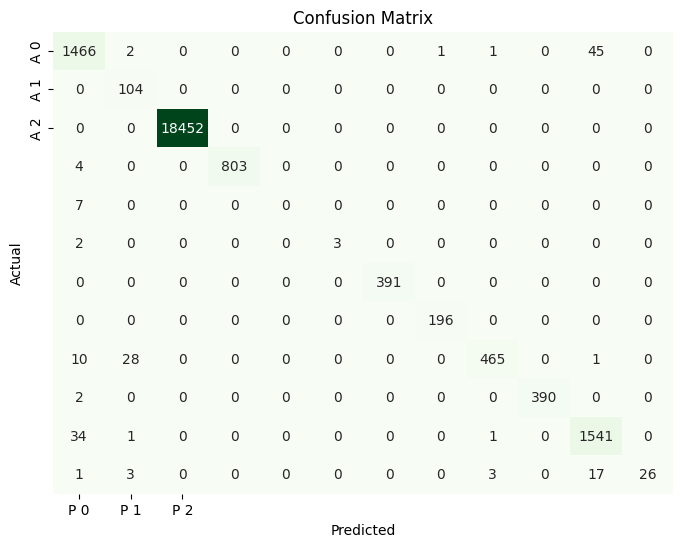

In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict on validation set
y_val_pred_probs = model.predict(X_val)
y_val_pred = np.argmax(y_val_pred_probs, axis=1)
y_val_true = np.argmax(y_val, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_val_true, y_val_pred)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_encoder.classes_)
# disp.plot(cmap='Greens', xticks_rotation=45)
# plt.title("Confusion Matrix on Validation Set")
# plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['P 0', 'P 1', 'P 2'],
            yticklabels=['A 0', 'A 1', 'A 2'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [15]:
from sklearn.metrics import classification_report
y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_val, axis=1)
print(classification_report(y_true, y_pred_classes))

750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1515
           1       0.75      1.00      0.86       104
           2       1.00      1.00      1.00     18452
           3       1.00      1.00      1.00       807
           4       0.00      0.00      0.00         7
           5       1.00      0.60      0.75         5
           6       1.00      1.00      1.00       391
           7       0.99      1.00      1.00       196
           8       0.99      0.92      0.95       504
           9       1.00      0.99      1.00       392
          10       0.96      0.98      0.97      1577
          11       1.00      0.52      0.68        50

    accuracy                           0.99     24000
   macro avg       0.89      0.83      0.85     24000
weighted avg       0.99      0.99      0.99     24000



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [18]:
print(cm)


[[ 1466     2     0     0     0     0     0     1     1     0    45     0]
 [    0   104     0     0     0     0     0     0     0     0     0     0]
 [    0     0 18452     0     0     0     0     0     0     0     0     0]
 [    4     0     0   803     0     0     0     0     0     0     0     0]
 [    7     0     0     0     0     0     0     0     0     0     0     0]
 [    2     0     0     0     0     3     0     0     0     0     0     0]
 [    0     0     0     0     0     0   391     0     0     0     0     0]
 [    0     0     0     0     0     0     0   196     0     0     0     0]
 [   10    28     0     0     0     0     0     0   465     0     1     0]
 [    2     0     0     0     0     0     0     0     0   390     0     0]
 [   34     1     0     0     0     0     0     0     1     0  1541     0]
 [    1     3     0     0     0     0     0     0     3     0    17    26]]


In [20]:
from sklearn.metrics import matthews_corrcoef

matthews_corrcoef(y_val_true, y_val_pred)

np.float64(0.9829577769333411)